### 0. Required run configuration — single episode
Full-scan SAITS reconstruction pretraining only. Choose one raw episode by ID or path.
The section order follows `train_cnn_mlp_baseline_single_episode.ipynb`.
The target is the same **15 × 716** measured range scan. SAITS additionally uses causal
measured LiDAR history and explicit masks, so input information differs from the state-only CNN/MLP.
There is no BarrierNet, certificate, dynamics rollout, or second training stage.
Validation is later scans of this same episode, not unseen-route generalization.


In [1]:
from pathlib import Path
import copy, json, math, random, sys
REPO_HINT = Path(r"A:\Projects\ARES")
if str(REPO_HINT / "scripts") not in sys.path:
    sys.path.insert(0, str(REPO_HINT / "scripts"))
def validate_config(config):
    for section in ('paths','run','data','model','training','runtime','scheduler','plots','faults'):
        
        if not isinstance(config.get(section),dict): raise ValueError(f'Missing CONFIG.{section}')
    required=dict(paths=('repo_root','output_root'),run=('name','seed'),data=('episode_path','train_fraction','val_fraction','split_policy','verify_hashes'),
        
        model=('window_size','d_model','n_heads','d_ff','n_layers','head_width','dropout'),
        training=('optimizer','loss','epochs','batch_size','learning_rate','weight_decay','betas','eps','patience','save_every_n_epochs','auxiliary_weight','observed_weight','clip_grad_norm','early_stopping'),
        runtime=('device','gpu_index','amp_dtype','num_workers','pin_memory','persistent_workers','cudnn_benchmark','matmul_precision','fused_adamw'),
        scheduler=('name','t_max_epochs','min_lr'),plots=('dpi','scan_index','range_min_m','range_max_m','colormap'),
        faults=('profiles','initial_healthy_scans','short_outage_scans','long_outage_scans','recovery_scans'))
    
    for section,keys in required.items():
        for key in keys:
            if key not in config[section]: raise ValueError(f'Missing CONFIG.{section}.{key}')
    
    def check(value,path):
        if value is None or isinstance(value,str) and not value.strip(): raise ValueError(f'Fill {path}')
        
        if isinstance(value,float) and not math.isfinite(value): raise ValueError(f'Nonfinite {path}')
        
        if isinstance(value,dict):
            for k,v in value.items(): check(v,path+'.'+k)
        
        elif isinstance(value,(list,tuple)):
            if not value: raise ValueError(f'Empty {path}')
            for i,v in enumerate(value): check(v,path+'.'+str(i))
    
    check(config,'CONFIG')
    d,m,t,r,s,f = [config[k] for k in ('data','model','training','runtime','scheduler','faults')]
    
    if d['split_policy']!='chronological' or not 0<d['train_fraction']<1 or not math.isclose(d['train_fraction']+d['val_fraction'],1):
        raise ValueError('Use chronological train/validation fractions summing to one.')
    
    for section,keys in ((m,('window_size','d_model','n_heads','d_ff','n_layers','head_width')), (t,('epochs','batch_size','patience'))):
        for key in keys:
            if isinstance(section[key],bool) or not isinstance(section[key],int) or section[key]<1: raise ValueError(f'{key} must be positive integer')
    
    if m['window_size']<2 or m['d_model']%2 or m['d_model']%m['n_heads'] or not 0<=m['dropout']<1: raise ValueError('Invalid attention dimensions/dropout')
    
    if r['device'] not in ('cuda','cpu') or r['amp_dtype'] not in ('bf16','fp16'): raise ValueError('Invalid runtime device/precision')
    
    if t['optimizer']!='adamw' or t['loss']!='mse' or s['name']!='cosine' or s['t_max_epochs']<t['epochs']: raise ValueError('Use AdamW/MSE and cosine covering the full run')
    
    if not 0 <= s['min_lr'] <= t['learning_rate'] or t['weight_decay']<0 or t['auxiliary_weight']<0 or t['observed_weight']<0: raise ValueError('Invalid optimization settings')
    
    if not set(f['profiles'])<= {'healthy','intermittent','long'} or len(set(f['profiles']))!=len(f['profiles']) or not set(f['profiles'])&{'intermittent','long'}: raise ValueError('Profiles need at least one outage condition')
    
    for key in ('short_outage_scans','long_outage_scans'):
        a,b=f[key]
        if not isinstance(a,int) or not isinstance(b,int) or not 1<=a<=b: raise ValueError('Invalid outage lengths')
    
    if f['initial_healthy_scans']<1 or f['recovery_scans']<1: raise ValueError('Fault healthy/recovery lengths must be positive')
    
    if r['num_workers'] < 0 or r['persistent_workers'] and r['num_workers']==0: raise ValueError('Invalid loader workers')
    
    if t['clip_grad_norm'] <=0 or t['eps'] <=0 or len(t['betas'])!=2 or any(not 0<=b<1 for b in t['betas']): raise ValueError('Invalid optimizer parameters')
    
    if not config['run']['name'] or any(c in config['run']['name'] for c in '<>:"/\\|?*'): raise ValueError('Use a Windows-safe run name')
    
    for section,key in [('run','seed'),('runtime','gpu_index'),('runtime','num_workers'),('training','save_every_n_epochs'),('plots','scan_index')]:
        value=config[section][key]
        if isinstance(value,bool) or not isinstance(value,int) or value<0: raise ValueError(f'{section}.{key} must be a nonnegative integer')
    
    for section,key in [('data','verify_hashes'),('training','early_stopping'),('runtime','pin_memory'),('runtime','persistent_workers'),('runtime','cudnn_benchmark'),('runtime','fused_adamw')]:
        if not isinstance(config[section][key],bool): raise ValueError(f'{section}.{key} must be boolean')
    
    if r['matmul_precision'] not in ('highest','high','medium'): raise ValueError('Invalid matmul precision')
    
    if not 0 <= config['plots']['range_min_m'] < config['plots']['range_max_m'] or config['plots']['dpi'] < 1: raise ValueError('Invalid plot settings')
    json.dumps(config,allow_nan=False)
    
    return config

def resolve_episode_directory(repo_root, episode_path):
    """Accept an episode ID, data/raw/<ID>, or an absolute raw episode folder."""
    root = Path(repo_root).expanduser().resolve()
    raw_root = (root / "data" / "raw").resolve()
    value = Path(episode_path).expanduser()
    if not value.is_absolute():
        value = raw_root / value if len(value.parts) == 1 else root / value
    value = value.resolve()
    if value.parent != raw_root:
        raise ValueError("Select one episode folder directly inside repo_root/data/raw.")
    return value

CONFIG = {'paths': {'repo_root': 'A:\\Projects\\ARES',
           'output_root': 'A:\\Projects\\ARES\\results\\saits_dense_single_episode'},
 'run': {'name': 'SAITS_BASELINE_SINGLE_EPISODE', 'seed': 42},
 'data': {'episode_path': 'A:\\Projects\\ARES\\data\\raw\\f9ab72ef-e1d7-4479-8faa-03bb5b36776c',
          'train_fraction': 0.8,
          'val_fraction': 0.2,
          'split_policy': 'chronological',
          'verify_hashes': True},
 'model': {'window_size': 80,
           'd_model': 64,
           'n_heads': 4,
           'd_ff': 128,
           'n_layers': 1,
           'head_width': 128,
           'dropout': 0.15},
 'training': {'optimizer': 'adamw',
              'loss': 'mse',
              'epochs': 500,
              'batch_size': 16,
              'learning_rate': 1e-4,
              'weight_decay': 1e-3,
              'betas': [0.9, 0.999],
              'eps': 1e-8,
              'patience': 35,
              'save_every_n_epochs': 20,
              'auxiliary_weight': 0.05,
              'observed_weight': 0.2,
              'clip_grad_norm': 1.0,
              'early_stopping': False},
 'scheduler': {'name': 'cosine', 't_max_epochs': 2000, 'min_lr': 1e-5},
 'runtime': {'gpu_index': 0,
             'amp_dtype': 'bf16',
             'num_workers': 0,
             'pin_memory': True,
             'persistent_workers': False,
             'cudnn_benchmark': True,
             'matmul_precision': 'high',
             'fused_adamw': True,
             'device': 'cuda'},
 'plots': {'dpi': 160,
           'scan_index': 0,
           'range_min_m': 0.0,
           'range_max_m': 7.0,
           'colormap': 'viridis'},
 'faults': {'profiles': ['healthy', 'intermittent', 'long'],
            'initial_healthy_scans': 30,
            'short_outage_scans': [15, 30],
            'long_outage_scans': [50, 70],
            'recovery_scans': 20}}

validate_config(CONFIG)
REPO_ROOT = Path(CONFIG["paths"]["repo_root"]).expanduser().resolve()
EPISODE_PATH = CONFIG["data"]["episode_path"]
OUTPUT_ROOT = Path(CONFIG["paths"]["output_root"]).expanduser().resolve()
print("Configuration validated. Output root:", OUTPUT_ROOT)


Configuration validated. Output root: A:\Projects\ARES\results\saits_dense_single_episode


### 1. Locate the configured single episode


In [2]:
import os
import platform
import shutil
import subprocess

PYTHON = Path(sys.executable).resolve()
EPISODE_DIR = resolve_episode_directory(REPO_ROOT, EPISODE_PATH)
NPZ_PATH = (REPO_ROOT / "data" / "processed" / "lidar_episode_v1"
            / EPISODE_DIR.name / "episode.npz")
required = [EPISODE_DIR / "manifest.json", NPZ_PATH]
missing = [str(path) for path in required if not path.is_file()]
if missing:
    raise FileNotFoundError(
        "Missing selected episode inputs: " + repr(missing)
        + ". The raw episode must have an existing lidar_episode_v1 Python export."
    )
print("Notebook kernel:", PYTHON)
print("Platform:", platform.platform())
print("Selected raw episode:", EPISODE_DIR)
print("Exported scans:", NPZ_PATH)


Notebook kernel: A:\Projects\ARES\.venv\Scripts\python.exe
Platform: Windows-10-10.0.26200-SP0
Selected raw episode: A:\Projects\ARES\data\raw\f9ab72ef-e1d7-4479-8faa-03bb5b36776c
Exported scans: A:\Projects\ARES\data\processed\lidar_episode_v1\f9ab72ef-e1d7-4479-8faa-03bb5b36776c\episode.npz


### 2. Check packages and CUDA


In [3]:
import importlib.util
from importlib.metadata import version as package_version

required_packages = ("numpy", "pandas", "torch", "matplotlib", "scipy")
missing = [name for name in required_packages if importlib.util.find_spec(name) is None]
if missing:
    raise RuntimeError("Install these packages in the active notebook environment: " + repr(missing))
print({name: package_version(name) for name in required_packages})


{'numpy': '2.4.6', 'pandas': '3.1.1', 'torch': '2.11.0+cu128', 'matplotlib': '3.11.2', 'scipy': '1.17.1'}


In [4]:
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader, TensorDataset

if tuple(int(part) for part in torch.__version__.split("+")[0].split(".")[:2]) < (2, 5):
    raise RuntimeError("This notebook requires PyTorch >= 2.5.")
if not torch.cuda.is_available():
    raise RuntimeError("CUDA is unavailable in this notebook kernel.")
if CONFIG["runtime"]["gpu_index"] >= torch.cuda.device_count():
    raise ValueError("Configured GPU index is unavailable.")
torch.cuda.set_device(CONFIG["runtime"]["gpu_index"])
if CONFIG["runtime"]["amp_dtype"] == "bf16" and not torch.cuda.is_bf16_supported():
    raise ValueError("Configured BF16 is unsupported; select fp16 explicitly.")
if CONFIG["plots"]["colormap"] not in plt.colormaps():
    raise ValueError("Unknown plots.colormap.")
print("GPU:", torch.cuda.get_device_name(CONFIG["runtime"]["gpu_index"]))
print("AMP:", CONFIG["runtime"]["amp_dtype"])


GPU: NVIDIA GeForce RTX 4080 Laptop GPU
AMP: bf16


### 3. Model and angle preprocessing
A 50-row historical window contains 10,740 physical beam ranges plus the same 12 sine/cosine
motion features used by CNN/MLP. Only training rows fit motion normalization. Masked inputs
are zero-filled; healthy no-return beams remain observed 7 m values.
Two diagonally masked self-attention imputation blocks form **one reconstruction model**.
The second dense head and attention mixture gate use `head_width` bottlenecks to avoid
quadratic 10,752 × 10,752 projections. This is an explicit SAITS endpoint adaptation,
not an upstream SAITS checkpoint-compatible implementation. MIT attribution is retained.


In [5]:
from dense_saits_single_episode import encode_sensor_state, normalize_history


In [6]:
from dense_saits_single_episode import DenseSaitsReconstructor


In [7]:
check_device = torch.device("cuda", CONFIG["runtime"]["gpu_index"])
with torch.inference_mode():
    check_model = DenseSaitsReconstructor(CONFIG["model"]).to(check_device).eval()
    check_history = torch.zeros(2, CONFIG["model"]["window_size"], 10752, device=check_device)
    check_mask = torch.zeros_like(check_history, dtype=torch.bool)
    check_output = check_model(check_history, check_mask)["prediction"]
    assert check_output.shape == (2, 10740)
    print("Full scan:", tuple(check_output.reshape(2, 716, 15).transpose(1, 2).shape))
    print("Parameters:", sum(p.numel() for p in check_model.parameters()))
del check_model, check_history, check_mask, check_output


Full scan: (2, 15, 716)
Parameters: 7683816


In [8]:
from dense_saits_single_episode import seed_training, write_json, save_checkpoint
from dense_saits_single_episode import plot_run_history, plot_validation_example


### 4. Seed the configured run


In [9]:
seed_training(CONFIG["run"]["seed"])


### 5. Load one healthy episode and freeze chronological folds
The first configured fraction of native scans is training; the remainder is validation.
Split IDs are frozen **before** normalization and artificial outages. All augmented copies
of a scan stay in its fold. Windows never cross the split boundary. Each fold starts with
missing padding, never future scans. The train/validation ratio matches the CNN notebook.
Check the validation metrics' `no_return_only` flag: the end of this route can be entirely
7 m no-return data. Such error scores do not assess obstacle reconstruction.


In [10]:
from dense_saits_single_episode import build_dataset


In [11]:
validate_config(CONFIG)
d = CONFIG["data"]
corpus = build_dataset(
    REPO_ROOT, episode_path=d["episode_path"],
    train_fraction=d["train_fraction"], val_fraction=d["val_fraction"],
    split_policy=d["split_policy"], verify_hashes=d["verify_hashes"],
)
print("Episode:", corpus.episode_id)
for name, ids in corpus.splits.items():
    info = corpus.diagnostics[name]
    print(f"{name}: {len(ids)} scans; {info['first_time_s']:.1f}s to {info['last_time_s']:.1f}s")
assert set(corpus.splits["train"]).isdisjoint(corpus.splits["validation"])


Episode: f9ab72ef-e1d7-4479-8faa-03bb5b36776c
train: 241 scans; 0.0s to 24.0s
validation: 61 scans; 24.1s to 30.1s


### 6. Training function: mini-batches, cosine decay, saved provenance
AdamW, CUDA BF16/FP16, cosine learning rate, uniquely named output folders, best/last
checkpoints, metrics CSV/JSON, training log and figures follow the CNN workflow.
A masked-target MSE plus observed/auxiliary terms trains the single reconstruction stage.
Best-checkpoint selection uses MSE on **hidden beams**, in metres², without clipping.
Early stopping is explicit in CONFIG (disabled by default, matching the current CNN loop).
There is no train/test/validation trajectory split or closed-loop fine-tuning in this experiment.


In [12]:
from dense_saits_single_episode import train_saits_baseline


### 7. Build train and validation tensors from the selected episode
Lazy CPU datasets create masked windows on demand instead of allocating overlapping dense
windows for the whole episode. Short and long scan outages alter inputs only; clean labels
are retained. Fault schedules are seeded and fixed for validation. Long outages can exceed
all 50 history rows. No reconstructed scan is falsely marked measured.


In [13]:
from dense_saits_single_episode import build_train_val_tensors


### 8. Train and save a new single-episode run
The seed is set before creating the model. `source.json`, `splits.json` and `normalizer.json`
record the episode hashes, fold IDs and training-only statistics. Existing runs are never overwritten.
Run the next two code cells to train. This notebook does not automatically launch MATLAB.


In [14]:
train_dataset, val_dataset, normalizer = build_train_val_tensors(corpus, CONFIG)
print("Native scans:", {name: len(ids) for name, ids in corpus.splits.items()})
print("Augmented endpoints:", len(train_dataset), len(val_dataset))
print("History / mask:", train_dataset[0][0].shape, train_dataset[0][1].shape)
print("Target:", train_dataset[0][2].shape, "= elevation-fastest full scan")


Native scans: {'train': 241, 'validation': 61}
Augmented endpoints: 723 183
History / mask: torch.Size([80, 10752]) torch.Size([80, 10752])
Target: torch.Size([10740]) = elevation-fastest full scan


In [15]:
validate_config(CONFIG)
seed_training(CONFIG["run"]["seed"])
model, history, run_dir = train_saits_baseline(
    DenseSaitsReconstructor(CONFIG["model"]), train_dataset, val_dataset,
    config=CONFIG, split_ids=corpus.splits,
    source_metadata=corpus.source_metadata, normalizer=normalizer,
)
print("Run saved to:", run_dir)
print(json.loads((run_dir / "summary.json").read_text())["validation_metrics"])


epoch=001/500 | train_mse=38.82763 | val_hidden_mse=26.05675 | val_mae=4.32250 | lr=1.00e-04 | 7.6s | BEST
epoch=002/500 | train_mse=15.28213 | val_hidden_mse=5.62158 | val_mae=1.60848 | lr=1.00e-04 | 7.0s | BEST
epoch=003/500 | train_mse=5.53348 | val_hidden_mse=2.15927 | val_mae=1.08983 | lr=1.00e-04 | 7.0s | BEST
epoch=004/500 | train_mse=3.29844 | val_hidden_mse=2.12100 | val_mae=1.27980 | lr=1.00e-04 | 7.2s | BEST
epoch=005/500 | train_mse=2.71323 | val_hidden_mse=0.76177 | val_mae=0.63946 | lr=1.00e-04 | 7.1s | BEST
epoch=006/500 | train_mse=2.37718 | val_hidden_mse=1.13228 | val_mae=0.87309 | lr=1.00e-04 | 7.1s | stale=1
epoch=007/500 | train_mse=2.17663 | val_hidden_mse=1.19861 | val_mae=0.92889 | lr=1.00e-04 | 7.4s | stale=2
epoch=008/500 | train_mse=2.20544 | val_hidden_mse=1.01951 | val_mae=0.80894 | lr=1.00e-04 | 7.7s | stale=3
epoch=009/500 | train_mse=2.05893 | val_hidden_mse=0.56019 | val_mae=0.54033 | lr=1.00e-04 | 8.8s | BEST
epoch=010/500 | train_mse=2.04258 | val_hid

### 9. Visualize saved results
The same saved loss, learning-rate and measured/predicted/error scan figures are generated.
The scan figure chooses a hidden-LiDAR example. Predictions are evaluated unclipped; only
the later MATLAB point-cloud adapter clips ranges to [0,7] m, as in CNN/MLP.
After training, use `scripts/captureSaitsSingleEpisodeSingleUav.m`. Set
`SaitsSingleEpisodeIdOverride` and optionally `SaitsSingleEpisodeTrainingRunDirectoryOverride`
to the printed `run_dir`. It exports and validates native MATLAB inference, then uses the
original VFH/PID and seed-513 intermittent faults. No BarrierNet or Python host runs online.


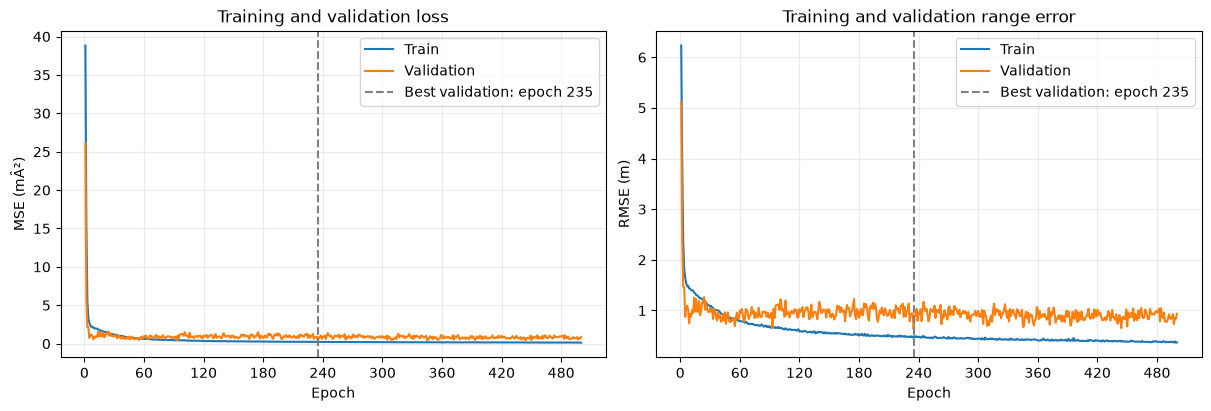

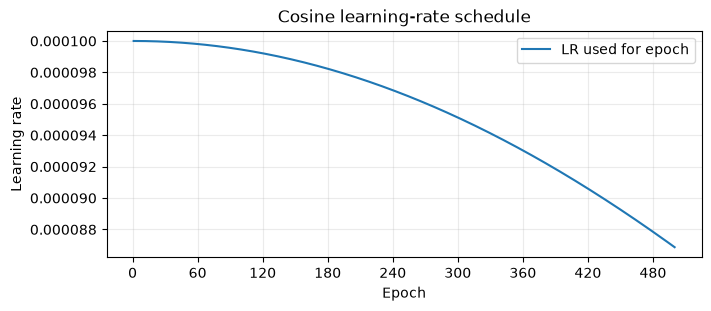

In [16]:
plot_run_history(run_dir, show=True)


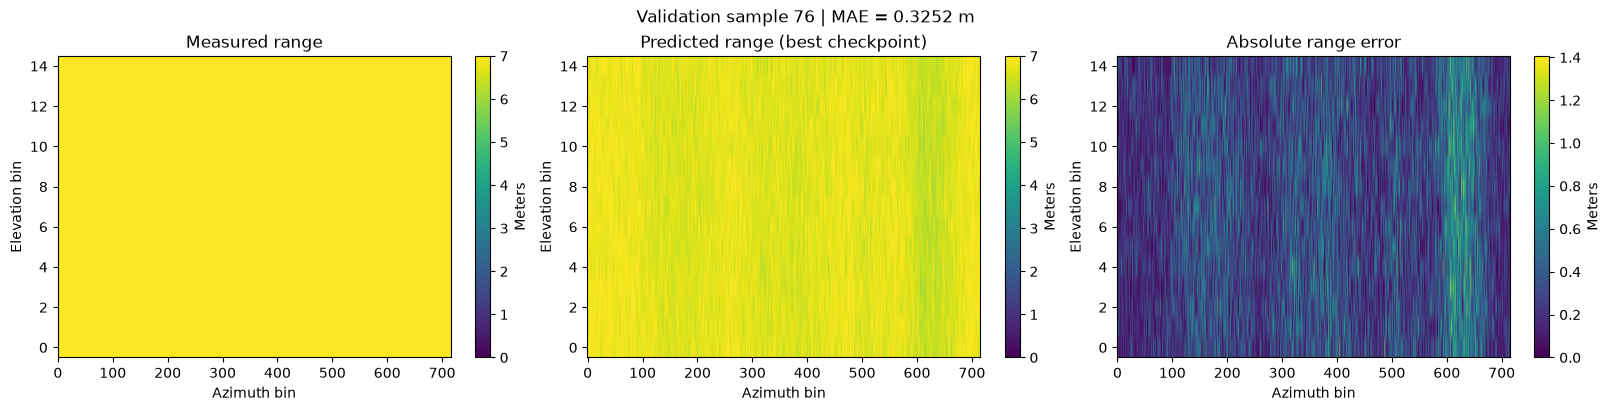

In [17]:
plot_validation_example(model, val_dataset, run_dir, show=True)
